# Exercise Sheet for Interpolation and Approximation
----------------------------------------------------------

In [1]:
#load some python packages you will need
import numpy as np                 #this helps compute things
import matplotlib.pyplot as plt    #this helps plot things

## Question 1
### a) Compute via interpolation and plot the Lagrange polynomial p(x) to $f(x) = cos(-2\pi x) + 0.4x^2$ over
### $(x_i,y_i) = [(7.2,21.04),(7.4,21.12),(7.6,22.39),(7.8,24.77]$ 


### b) Estimate the maximum absolute error bound for this Lagrange polynomial approximation over $\xi \in [x_0,x_n]$

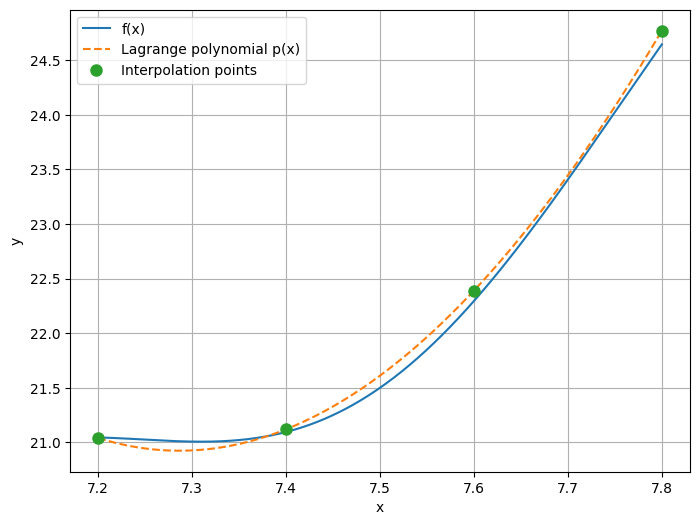

In [2]:
#a)
from scipy.interpolate import BarycentricInterpolator
import numpy as np             
import matplotlib.pyplot as plt  
xi = np.array([7.2, 7.4, 7.6, 7.8])
yi = np.array([21.04, 21.12, 22.39, 24.77])
p = BarycentricInterpolator(xi, yi)
x = np.linspace(7.2, 7.8, 500)
f = np.cos(-2*np.pi*x) + 0.4*x**2
plt.figure(figsize=(8, 6))
plt.plot(x, f, label='f(x)')
plt.plot(x, p(x), '--', label='Lagrange polynomial p(x)')
plt.plot(xi, yi, 'o', markersize=8, label='Interpolation points')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid()
plt.show()

In [3]:
#b)
import math
x = np.linspace(7.2, 7.8, 10000)
M = (2*np.pi)**4
product = np.abs((x-7.2)*(x-7.4)*(x-7.6)*(x-7.8))
error_bound = M / math.factorial(4) * np.max(product)
print("maximum absolute error bound:", error_bound)

maximum absolute error bound: 0.10390303003425343


In [4]:
x = np.arange(7,8,0.001)   #dummy range for function
y = np.cos(-2*np.pi*x) +0.4*x**2  #function f(x)

In [5]:
xi = np.array((7.2,7.4,7.6,7.8))   # points for interpolation
yi = y[np.digitize(xi,x)]

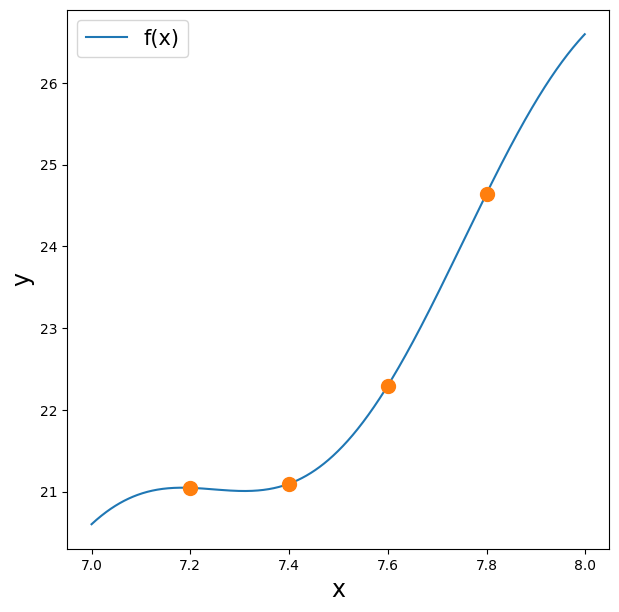

In [6]:
plt.figure(figsize=(7,7))
plt.plot(x,y,label='f(x)')  
plt.plot(xi,yi,'o',markersize=10)
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend(loc='best',fontsize=15)

----------------------------------------------------------

## Question 2
### Assume linear interpolation with step size $\textbf{d}$ is used to approximate $y(x) = \pi x^7$
### What step size for linear interpolation do you need to have for an absolute error $E_{max} < 10^{-6}$?. You can assume  $x \in [0,2]$.

In [7]:
import numpy as np
M = 42 * np.pi * 2**5
Emax = 1e-6
d = np.sqrt(8 * Emax / M)
print("Maximum step size:", d)

Maximum step size: 4.3528171377568164e-05


## Question 3
### When using Taylor polynomials to approximate $y = cos(-3 \pi x) + 3x$ over the range $x = [-0.25,0.25]$, about $x= 0$;  to what order $j$ would you need to compute the interpolating polynomial in order to keep the maximum absolute error smaller than $E_{j}(x) < 10^{-6}$?

Text(0, 0.5, 'y')

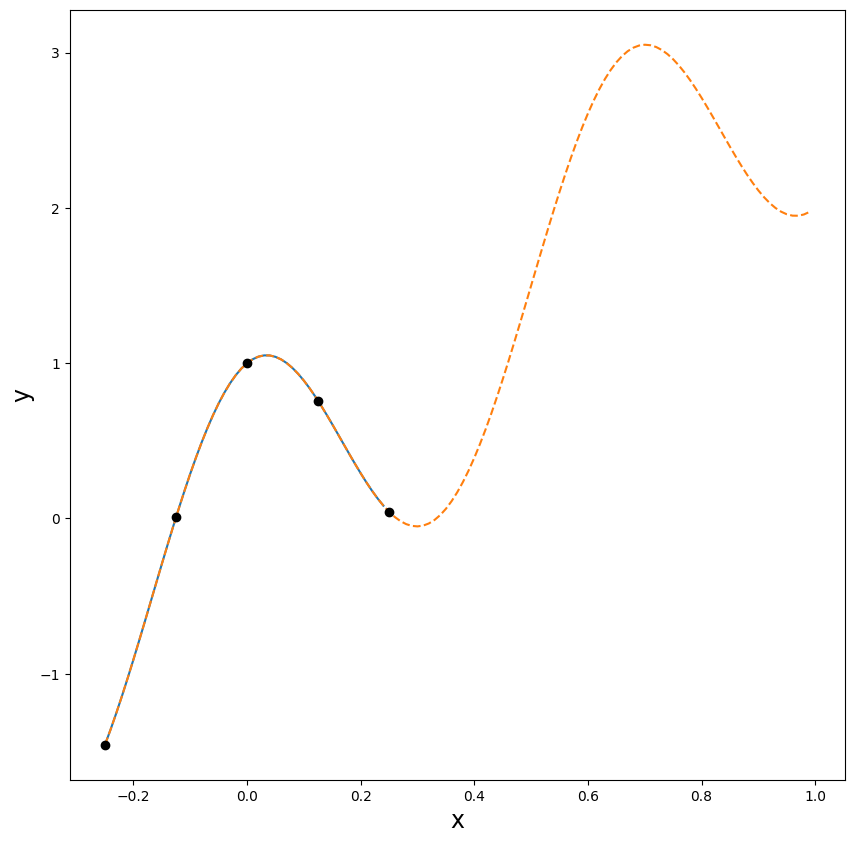

In [8]:
xi = np.arange(-0.25,1,0.01)
xdum = np.arange(-0.25,0.25,0.01)
x = np.array([-0.25,-0.125,0,0.125,0.25])
y = np.cos(-3*np.pi*x) + 3*x
ydum = np.cos(-3*np.pi*xdum) + 3*xdum
yi = np.cos(-3*np.pi*xi) + 3*xi
plt.figure(figsize=(10,10))
plt.plot(xdum,ydum)
plt.plot(xi,yi,'--')
plt.plot(x,y,'o',c='black')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)

In [9]:
import numpy as np
import math
for j in range(1, 30):
    error = (3*np.pi*0.25)**(j+1) / math.factorial(j+1)
    print(j, error)
    if error < 1e-6:
        print("Required order j =", j)
        break

1 2.775826237806382
2 2.1801288290835807
3 1.2842018837490554
4 0.6051658805568308
5 0.23764808557006725
6 0.07999215854642162
7 0.023559635403208892
8 0.006167898125331254
9 0.0014532767578973194
10 0.000311291153607478
11 6.112187508129656e-05
12 1.1078078868982747e-05
13 1.8644363137866708e-06
14 2.92864971323912e-07
Required order j = 14


----------------------------------------------------------

## Question 4
## Use bilinear interpolation to determine the value of the function $f(x,y) = z$  at the point $(x_r, y_r)$, given the below four data points $x_i, y_i$ with values $z_{i} = f(x_i,y_i)$


Text(0.4032820368190092, 0.5871771435525632, '($x_r,y_r)$')

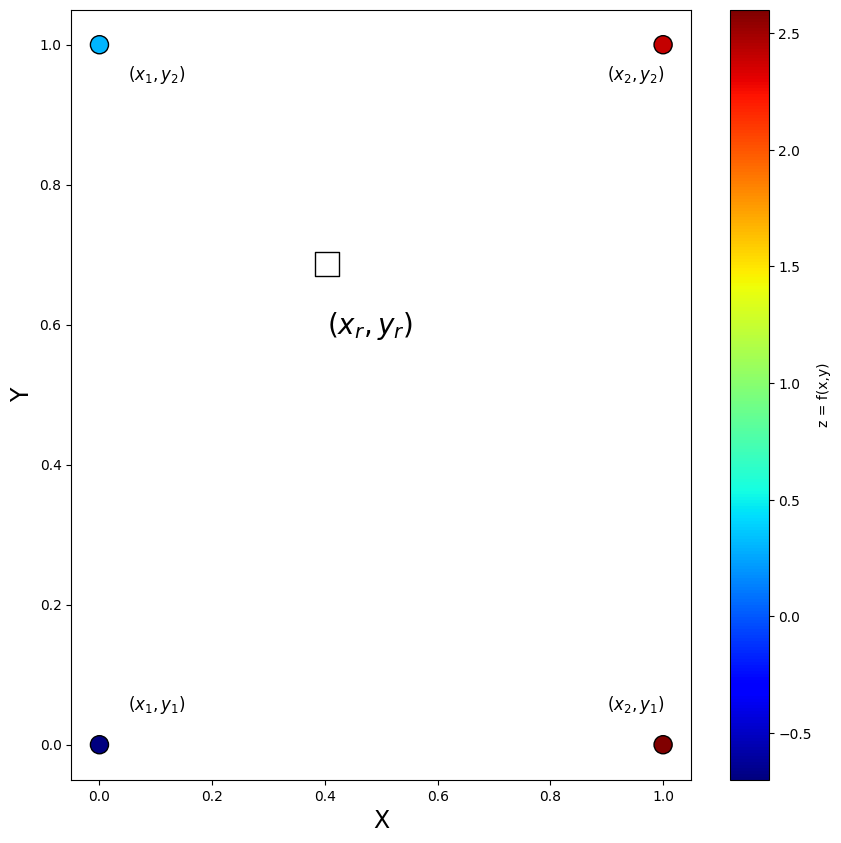

In [10]:
#Known data points and function values.  Listed clockwise from the x_1,y_1 = (0,0) point.
xi = np.array([0,0,1,1])  #x_1,x_1,x_2,x_2
yi = np.array([0,1,1,0])  #y_1,y_2,y_2,y_1
zi = np.array([-0.7,0.3,2.4,2.6])  

#Randomly generate coordinates to find function value (z = f(x,y)) at 
xr = np.random.uniform()
yr = np.random.uniform()

#Visualize
plt.figure(figsize=(10,10))
plt.scatter(xi,yi,c=zi,s=170,marker='o',cmap='jet',edgecolor='black')
plt.colorbar(label='z = f(x,y)')
plt.xlabel('X',fontsize=17)
plt.ylabel('Y',fontsize=17)
plt.scatter(xr,yr,edgecolor='black',marker='s',s=290,c='white')
plt.text(0.05,0.05,'($x_1,y_1)$',fontsize=12)
plt.text(0.05,0.95,'($x_1,y_2)$',fontsize=12)
plt.text(0.9,0.95,'($x_2,y_2)$',fontsize=12)
plt.text(0.9,0.05,'($x_2,y_1)$',fontsize=12)
plt.text(xr,yr-0.1,'($x_r,y_r)$',fontsize=20)

In [12]:
z11 = -0.7
z12 = 0.3
z22 = 2.4
z21 = 2.6
# bilinear interpolation
zr = (z11 * (1-xr) * (1-yr)
      + z21 * xr * (1-yr)
      + z12 * (1-xr) * yr
      + z22 * xr * yr)

print("xr =", xr)
print("yr =", yr)
print("Interpolated z =", zr)

xr = 0.4032820368190092
yr = 0.6871771435525632
Interpolated z = 0.9854564273264779
